# Анализ клиентской базы e-commerce (Пет-проект)

## 1. О датасете
В качестве данных используется публичный датасет **Brazilian E-Commerce Public Dataset by Olist** (маркетплейс, 2016–2018 гг.). 
Он включает 8 связанных таблиц:

* **orders** — заказы (статус, ключевые таймстемпы);
* **customers** — информация о покупателях;
* **order_items** — товары в заказах (позиции, цена, доставка);
* **payments** — способы и суммы оплаты;
* **reviews** — оценки и отзывы клиентов;
* **products** — карточки товаров и их категории;
* **sellers** — данные продавцов;
* **category** — справочник перевода названий категорий с португальского на английский.

**Цель проекта:** отработать методологию расчета ключевых метрик (GMV, AOV) и клиентской сегментации (RFM), которая применима для маркетинговой аналитике в подписных сервисах (на примере СберПрайма).

In [5]:
import duckdb
import os
import matplotlib.pyplot as plt
import seaborn as sns


if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

base_path = "data/raw/"
con = duckdb.connect()

tables = {
    "orders":      base_path + "olist_orders_dataset.csv",
    "customers":   base_path + "olist_customers_dataset.csv",
    "order_items": base_path + "olist_order_items_dataset.csv",
    "payments":    base_path + "olist_order_payments_dataset.csv",
    "reviews":     base_path + "olist_order_reviews_dataset.csv",
    "products":    base_path + "olist_products_dataset.csv",
    "sellers":     base_path + "olist_sellers_dataset.csv",
    "category":    base_path + "product_category_name_translation.csv",
}

for name, path in tables.items():
    con.execute(f"CREATE OR REPLACE VIEW {name} AS SELECT * FROM read_csv_auto('{path}')")

print("Все таблицы успешно загружены в DuckDB")

Все таблицы успешно загружены в DuckDB


## 2. Проверка качества данных (Data Quality)
В реальных данных всегда есть аномалии. Проверим пропуски и нулевые значения в ключевых таблицах (`orders` и `payments`), чтобы понять, как правильно фильтровать данные для расчета метрик.

In [6]:
print("--- Аномалии в таблице orders ---")
display(con.execute("""
    SELECT 
        COUNT(*) AS total_rows,
        SUM(CASE WHEN order_delivered_customer_date IS NULL THEN 1 ELSE 0 END) AS null_delivered
    FROM orders
""").df())

print("\n--- Аномалии в таблице payments ---")
display(con.execute("""
    SELECT 
        COUNT(*) AS total_rows,
        SUM(CASE WHEN payment_value <= 0 THEN 1 ELSE 0 END) AS zero_or_negative_payments
    FROM payments
""").df())

--- Аномалии в таблице orders ---


,total_rows,null_delivered
0,99441,2965.0



--- Аномалии в таблице payments ---


,total_rows,zero_or_negative_payments
0,103886,9.0


###  Вывод по очистке данных

Проверка показала наличие аномалий:
1. **В таблице заказов** найдено **2 965 строк** с пустой датой доставки. Это отмененные заказы или заказы в процессе доставки.
2. **В таблице платежей** найдено **9 транзакций** с нулевой или отрицательной суммой (технические сбои).

**Как я это учитываю (Data Cleaning):** 
Чтобы не искажать бизнес-метрики (GMV и AOV), я не удаляю строки (чтобы сохранить историю), а применяем логические фильтры прямо в SQL-запросах:
* Для расчета выручки беру только успешно доставленные заказы: `WHERE order_status = 'delivered'`.
* Исключаю технический брак: `AND payment_value > 0`.

## 3. Ключевые бизнес-метрики (KPI)
Рассчитаем базовые показатели здоровья бизнеса: общую выручку (GMV), количество заказов и средний чек (AOV). А также найдем топ-10 категорий по выручке.

In [7]:
print("=== ОБЩИЕ KPI ===")
kpi_query = """
SELECT 
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(p.payment_value), 2) AS total_gmv,
    ROUND(SUM(p.payment_value) / COUNT(DISTINCT o.order_id), 2) AS aov
FROM orders o
JOIN payments p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered' 
  AND p.payment_value > 0;
"""
display(con.execute(kpi_query).df())

print("\n=== ТОП-10 КАТЕГОРИЙ ПО ВЫРУЧКЕ ===")
cat_query = """
SELECT 
    t.product_category_name_english AS category,
    ROUND(SUM(oi.price), 2) AS revenue,
    COUNT(DISTINCT oi.order_id) AS orders_count
FROM order_items oi
JOIN products pr ON oi.product_id = pr.product_id
JOIN category t ON pr.product_category_name = t.product_category_name
JOIN orders o ON oi.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY 1
ORDER BY revenue DESC
LIMIT 10;
"""
display(con.execute(cat_query).df())

=== ОБЩИЕ KPI ===


,total_orders,total_gmv,aov
0,96477,15422461.77,159.86



=== ТОП-10 КАТЕГОРИЙ ПО ВЫРУЧКЕ ===


,category,revenue,orders_count
0,health_beauty,1233131.72,8647
1,watches_gifts,1166176.98,5495
2,bed_bath_table,1023434.76,9272
3,sports_leisure,954852.55,7530
4,computers_accessories,888724.61,6530
5,furniture_decor,711927.69,6307
6,housewares,615628.69,5743
7,cool_stuff,610204.10,3559
8,auto,578966.65,3810
9,toys,471286.48,3804


###  Выводы по метрикам
* **AOV (Средний чек)** составил около **160 реалов** (бразильская валюта)
* **Бизнес-инсайт:** Категория `bed_bath_table` лидирует по количеству заказов, но уступает по выручке категории `health_beauty`. Это значит, что в «Красоте» выше средний чек. В контексте маркетинга — на товары для дома нужно делать допродажи, а «Красоту» продвигать как премиум-сегмент.

## 4. RFM-сегментация клиентов
Чтобы не тратить бюджет на всех подряд, разделим клиентов на группы по трем параметрам: Recency (давность), Frequency (частота), Monetary (сумма). Это стандартная практика для удержания клиентов (Retention) и снижения оттока (Churn).

In [10]:
rfm_query = """
WITH customer_orders AS (
    SELECT 
        c.customer_unique_id,
        MAX(DATE(o.order_purchase_timestamp)) AS last_purchase_date,
        COUNT(DISTINCT o.order_id) AS frequency,
        SUM(p.payment_value) AS monetary
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN payments p ON o.order_id = p.order_id
    WHERE o.order_status = 'delivered' AND p.payment_value > 0
    GROUP BY 1
),
rfm_scores AS (
    SELECT 
        customer_unique_id, frequency, monetary,
        DATE_DIFF('day', last_purchase_date, (SELECT MAX(DATE(order_purchase_timestamp)) FROM orders)) AS recency_days,
        NTILE(5) OVER (ORDER BY DATE_DIFF('day', last_purchase_date, (SELECT MAX(DATE(order_purchase_timestamp)) FROM orders)) DESC) AS r_score,
        NTILE(5) OVER (ORDER BY frequency ASC) AS f_score,
        NTILE(5) OVER (ORDER BY monetary ASC) AS m_score
    FROM customer_orders
),
rfm_segments AS (
    SELECT 
        *,
        CASE 
            WHEN r_score >= 4 AND f_score >= 4 AND m_score >= 4 THEN '1. Чемпионы'
            WHEN r_score >= 3 AND f_score >= 3 AND m_score >= 3 THEN '2. Лояльные'
            WHEN r_score >= 4 AND f_score <= 2 THEN '3. Новички'
            WHEN r_score <= 2 AND f_score >= 3 THEN '4. В зоне риска'
            WHEN r_score <= 2 AND f_score <= 2 THEN '5. Спящие'
            ELSE '6. Остальные'
        END AS segment
    FROM rfm_scores
)
SELECT 
    segment,
    COUNT(customer_unique_id) AS customers_count,
    ROUND(AVG(recency_days), 0) AS avg_recency_days,
    ROUND(AVG(frequency), 1) AS avg_frequency,
    ROUND(AVG(monetary), 0) AS avg_monetary
FROM rfm_segments
GROUP BY 1
ORDER BY 1;
"""
rfm_df = con.execute(rfm_query).df()
display(rfm_df)

,segment,customers_count,avg_recency_days,avg_frequency,avg_monetary
0,1. Чемпионы,12665,155.0,1.1,309.0
1,2. Лояльные,14692,157.0,1.1,181.0
2,4. В зоне риска,11460,428.0,1.1,169.0
3,5. Спящие,25884,450.0,1.0,164.0
4,6. Остальные,28656,207.0,1.0,94.0


### Вывод по сегментации и связь со СберПраймом

* **«Чемпионы» (12 665 клиентов)** — ядро базы. Они покупали недавно (в среднем 155 дней назад) и тратят больше всех (309 реалов). Для них важна программа лояльности и ранний доступ к новинкам, а не скидки.
* **«В зоне риска» (11 460 клиентов)** — не покупали в среднем 428 дней, но исторически тратили много (169 реалов). Это зона потенциального Churn (оттока).
* **«Спящие» (25 884 клиента)** — самая большая группа, не покупали 450 дней.

**Связь с задачами СберПрайма:** 
В подписке эта же логика позволяет выявить пользователей, которые перестали пользоваться доставкой. Задача маркетинга — запустить для «Зоны риска» реактивационную кампанию (email/SMS с промокодом), чтобы не дать им отписаться, а «Чемпионов» стимулировать к продлению подписки через эксклюзивный сервис.

###  Визуализация RFM-сегментов
Построим график, чтобы наглядно увидеть, какая доля клиентов находится в целевых сегментах, а кто находится в зоне риска (потенциальный отток).

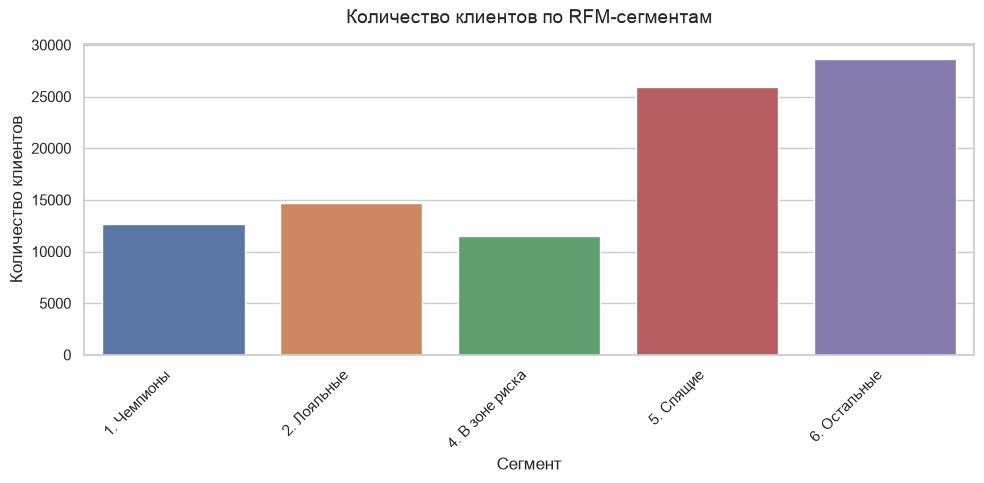

In [13]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))
sns.barplot(data=rfm_df, x='segment', y='customers_count', hue='segment', legend=False)
plt.title('Количество клиентов по RFM-сегментам', fontsize=14, pad=15)
plt.xlabel('Сегмент')
plt.ylabel('Количество клиентов')
plt.xticks(rotation=45, ha='right')

os.makedirs('output/figures', exist_ok=True)
plt.tight_layout()
plt.savefig('output/figures/rfm_segments.png', dpi=300)
plt.show()